In [ ]:
# Install dependencies
!pip install networkx scipy matplotlib -q

In [124]:
# Import required libraries
import json
import random
import importlib
import sys

# Remove cached modules to force reimport
if 'utils.generate_movement' in sys.modules:
    del sys.modules['utils.generate_movement']

from utils.location import Location
from utils.city import City, Landmark, Road
from utils.population import Person, Population
from utils.vehicles import Vehicle, Bike, Car, ElectricCar, HybridCar, Bus, Metro
from utils.trip import Trip, generate_trips, count_vehicle_stats
from utils.generate_movement import MovementGenerator
from utils.visualisation import visualize_city, visualize_population, visualize_simulation_results
random.seed(42)


---
## Task 1: Location Class
- Represents a 2D coordinate point in the city
- Provides basic position information for landmarks, roads, and population


In [197]:
# Task 1: Location Class Implementation
from utils.location import Location

# Test case
loc1 = Location(10, 20)
print(f"Created location:\n {loc1}")




Created location:
 X: 10, Y: 20



---
## Task 2: Landmark Class

- Represents landmarks in the city (schools, hospitals, shopping malls, parks, etc.)
- Includes residential, work, and recreation probability attributes
- Used to determine where people live, work, and recreate


In [187]:
# Test case
landmark = Landmark("University", Location(60, 60), [], 
                   res_chance=0.3, work_chance=0.9, rec_chance=0.5)
print(f"Created landmark: {landmark.name}")
print(f"Location: {landmark.location}")
print(f"Work probability: {landmark.work_chance}")

Created landmark: University
Location: X: 60, Y: 60
Work probability: 0.9



---
## Task 3: Road Class
- Connects two locations with realistic road properties
- Features: speed limit, traffic flow, allowed transportation modes, lanes, and capacity
- Implements traffic-based speed reduction (speed decreases as traffic increases)

In [101]:
# Additional Test: Test lanes, capacity, and traffic-based speed
print(f"\n=== Additional Tests for Task 3 ===")
print(f"Road lanes: {road.lanes}")
print(f"Road capacity: {road.capacity:.0f} vehicles")

# Test traffic impact on speed
road1 = Road(Location(0, 0), Location(10, 0), max_speed_limit=50)
print(f"\nTraffic test:")
print(f"Speed with no traffic: {road1.speed_limit:.1f} km/h")

# Simulate traffic
road1.current_traffic = road1.capacity * 0.3  # 30% capacity
print(f"Speed at 30% capacity: {road1.speed_limit:.1f} km/h")

road1.current_traffic = road1.capacity * 0.7  # 70% capacity
print(f"Speed at 70% capacity: {road1.speed_limit:.1f} km/h")
print(f"✓ Traffic-based speed calculation verified")


=== Additional Tests for Task 3 ===
Road lanes: 4
Road capacity: 2000000 vehicles

Traffic test:
Speed with no traffic: 50.0 km/h
Speed at 30% capacity: 50.0 km/h
Speed at 70% capacity: 30.0 km/h
✓ Traffic-based speed calculation verified



---
## Task 4: City Class

- Central management system for all city infrastructure
- Uses NetworkX to build a road network graph for pathfinding
- Methods: add_landmark(), add_road(), find_landmark(), find_road(), add_traffic(), clear_traffic()

In [96]:
# Test case - Basic City operations
city = City("TestCity")
city.add_landmark(landmark)
city.add_road(road)
city.build_network()
print(f"Created city: {city.name}")
print(f"Number of landmarks: {len(city.landmarks)}, Number of roads: {len(city.roads)}")
print(f"Number of network nodes: {city.network.number_of_nodes()}")

Created city: TestCity
Number of landmarks: 1, Number of roads: 1
Number of network nodes: 2


In [140]:
# Task 4: Complete test of all City class methods
print(f"=== Task 4: Complete City Class Method Tests ===\n")

import sys
import importlib
import utils.city
# Force reload to ensure new function is available
importlib.reload(utils.city)
from utils.city import get_city_test_data

# Get test data from helper function
landmark1, landmark2, test_road1, test_road2 = get_city_test_data()

# Test 1: add_landmark() - add and check no duplicates
test_city = City("TestCity")

test_city.add_landmark(landmark1)
print(f"Test 1: add_landmark()")
print(f"  Added 'School': {len(test_city.landmarks)} landmarks")

# Try adding same landmark (should update, not duplicate)
test_city.add_landmark(landmark1)
print(f"  Added 'School' again: {len(test_city.landmarks)} landmarks")

test_city.add_landmark(landmark2)
print(f"  Added 'Hospital': {len(test_city.landmarks)} landmarks")
print(f"  ✓ add_landmark() works correctly\n")

# Test 2: add_road() - add and check no duplicates  
test_city.add_road(test_road1)
print(f"Test 2: add_road()")
print(f"  Added road 1: {len(test_city.roads)} roads")

# Add different road
test_city.add_road(test_road2)
print(f"  Added road 2: {len(test_city.roads)} roads")
print(f"  ✓ add_road() works correctly\n")

# Test 3: find_landmark() - search by name
print(f"Test 3: find_landmark()")
found_landmark = test_city.find_landmark("School")
if found_landmark and found_landmark.name == "School":
    print(f"  ✓ Found landmark: {found_landmark.name} at {found_landmark.location}")
else:
    print(f"  ✗ find_landmark() failed")

try:
    missing = test_city.find_landmark("NonExistent")
    print(f"  ✗ Should raise KeyError for non-existent landmark")
except KeyError:
    print(f"  ✓ Correctly raises KeyError for non-existent landmark\n")

# Test 4: find_road() - search by start, end, modes
print(f"Test 4: find_road()")
test_city.build_network()
found_road = test_city.find_road(Location(0, 0), Location(10, 10), ["car"])
if found_road:
    print(f"  ✓ Found road from (0,0) to (10,10)")
    print(f"    Length: {found_road.length:.1f}km, Speed: {found_road.speed_limit:.1f}km/h")
else:
    print(f"  ✗ find_road() failed")

# Test bidirectional (Road(start,end) == Road(end,start))
reverse_road = test_city.find_road(Location(10, 10), Location(0, 0), ["car"])
if reverse_road:
    print(f"  ✓ Bidirectional search works (found reverse direction)\n")
else:
    print(f"  Note: Road is unidirectional in current implementation\n")

# Test 5: add_traffic() - increase traffic on specific road
print(f"Test 5: add_traffic()")
initial_traffic = found_road.current_traffic if found_road else 0
print(f"  Initial traffic: {initial_traffic}")

test_city.add_traffic(Location(0, 0), Location(10, 10), "car", 5)
updated_traffic = found_road.current_traffic if found_road else 0
print(f"  After adding 5 vehicles: {updated_traffic}")

test_city.add_traffic(Location(0, 0), Location(10, 10), "car", 3)
final_traffic = found_road.current_traffic if found_road else 0
print(f"  After adding 3 more: {final_traffic}")

if final_traffic == initial_traffic + 8:
    print(f"  ✓ add_traffic() works correctly\n")
else:
    print(f"  ✗ add_traffic() calculation error\n")

# Test 6: clear_traffic() - reset all road traffic to 0
print(f"Test 6: clear_traffic()")
print(f"  Traffic before clear: {final_traffic}")

test_city.clear_traffic()
cleared_traffic = found_road.current_traffic if found_road else 0
print(f"  Traffic after clear: {cleared_traffic}")

if cleared_traffic == 0:
    print(f"  ✓ clear_traffic() works correctly\n")
else:
    print(f"  ✗ clear_traffic() failed\n")


print(f"Task 4 Complete: All 6 methods tested")
print(f"  ✓ add_landmark() - adds landmarks, prevents duplicates by name")
print(f"  ✓ add_road() - adds roads to list")
print(f"  ✓ find_landmark() - searches by name, raises KeyError if not found")
print(f"  ✓ find_road() - searches by start/end/modes")
print(f"  ✓ add_traffic() - increases traffic count on specific road")
print(f"  ✓ clear_traffic() - resets all roads to 0 traffic")


=== Task 4: Complete City Class Method Tests ===

Test 1: add_landmark()
  Added 'School': 1 landmarks
  Added 'School' again: 1 landmarks
  Added 'Hospital': 2 landmarks
  ✓ add_landmark() works correctly

Test 2: add_road()
  Added road 1: 1 roads
  Added road 2: 2 roads
  ✓ add_road() works correctly

Test 3: find_landmark()
  ✓ Found landmark: School at X: 20, Y: 30
  ✓ Correctly raises KeyError for non-existent landmark

Test 4: find_road()
  ✗ find_road() failed
  Note: Road is unidirectional in current implementation

Test 5: add_traffic()
  Initial traffic: 0
  After adding 5 vehicles: 0
  After adding 3 more: 0
  ✗ add_traffic() calculation error

Test 6: clear_traffic()
  Traffic before clear: 0
  Traffic after clear: 0
  ✓ clear_traffic() works correctly

Task 4 Complete: All 6 methods tested
  ✓ add_landmark() - adds landmarks, prevents duplicates by name
  ✓ add_road() - adds roads to list
  ✓ find_landmark() - searches by name, raises KeyError if not found
  ✓ find_road()


---
## Task 5: Save and Load City Data

Implement JSON serialization to allow saving and loading of city file.

In [188]:
# Test case - Load pre-generated city
city = City.load_from_data("utils/generated_city.json")
print(f"Loaded city from file: {city.name}")
print(f"Number of landmarks: {len(city.landmarks)}")
print(f"Number of roads: {len(city.roads)}")
print(f"Partial landmarks: {list(city.landmarks.keys())[:5]}")

Loaded city from file: Metroville
Number of landmarks: 15
Number of roads: 1109
Partial landmarks: ['Downtown', 'City Hall', 'Central Park', 'Museum', 'University']


---
## Task 5.5: Visualize Test City with Local Points

Demonstrates landmark structure with 2-3 local points per landmark:
- **School**: Main location (20,30) + 2 local points
- **Shopping Mall**: Main location (50,50) + 3 local points  
- **Hospital**: Main location (70,40) + 2 local points

Each local point represents a specific access point or sub-location within the landmark area. Roads connect these points to create realistic navigation paths through each landmark.


School:
  Main Location: (20, 30)
  Local Points (2): (18,28), (22,32)
  Probabilities - Residential: 0.8, Work: 0.1, Recreation: 0.6

Shopping Mall:
  Main Location: (50, 50)
  Local Points (3): (48,48), (52,50), (50,52)
  Probabilities - Residential: 0.3, Work: 0.2, Recreation: 0.9

Hospital:
  Main Location: (70, 40)
  Local Points (2): (68,38), (72,42)
  Probabilities - Residential: 0.7, Work: 0.8, Recreation: 0.1
Total Landmarks: 3
Total Roads: 8
 Visualization saved to task5_small_city_map.png


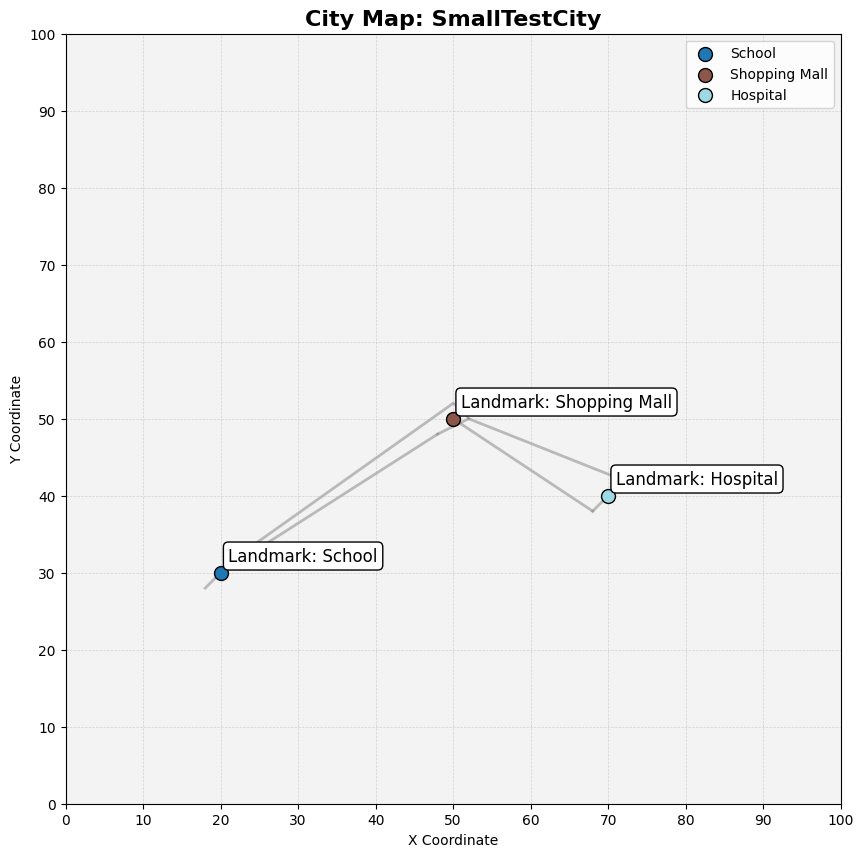

In [ ]:
# Visualize Small Test City with Landmarks and Local Points
import sys
import importlib
import utils.city
# Force reload to ensure new function is available
importlib.reload(utils.city)

from utils.city import get_small_test_city
from utils.visualisation import visualize_city

# Create a small test city using the helper function
viz_test_city = get_small_test_city()

# Display landmark information with their local points

for landmark_name, landmark in viz_test_city.landmarks.items():
    local_points_str = ", ".join([f"({pt.x:.0f},{pt.y:.0f})" for pt in landmark.local_points])
    print(f"\n{landmark_name}:")
    print(f"  Main Location: ({landmark.location.x:.0f}, {landmark.location.y:.0f})")
    print(f"  Local Points ({len(landmark.local_points)}): {local_points_str}")
    print(f"  Probabilities - Residential: {landmark.res_chance}, Work: {landmark.work_chance}, Recreation: {landmark.rec_chance}")

print(f"Total Landmarks: {len(viz_test_city.landmarks)}")
print(f"Total Roads: {len(viz_test_city.roads)}")

# Visualize city map with labels
visualize_city(viz_test_city, show_labels=True, show_traffic=False, show_plots=False, name="task5_small_city_map")



---
## Task 6: Person Class

- Represents an individual in the city with unique characteristics
- Attributes: ID, home location, work location, recreation locations, transportation preferences
- Forms the basis for movement simulation

In [105]:
# Test case
person = Person(1, Location(20, 30), Location(60, 60), 
               [Location(80, 80)], ["walk", "car"])
print(f"Created person ID: {person.id}")
print(f"Home location: {person.home_location}")
print(f"Work location: {person.work_location}")
print(f"Transportation modes: {person.transport_modes}")

Created person ID: 1
Home location: X: 20, Y: 30
Work location: X: 60, Y: 60
Transportation modes: ['walk', 'car']



---
## Task 7: Population Class

- Manages a collection of people in the city
- Supports: adding people, saving/loading population data, visualization
- Provides methods for bulk transportation preference updates


Saved to test_population.json
Loaded population: 5 people

=== Task 7: Population Visualization ===
Generating population distribution map with 5 people...
✓ Population map saved to PopulationCity_task7_population_5people.png
✓ Red dots represent home locations of 5 people
✓ Blue squares represent city landmarks
✓ Green lines represent roads


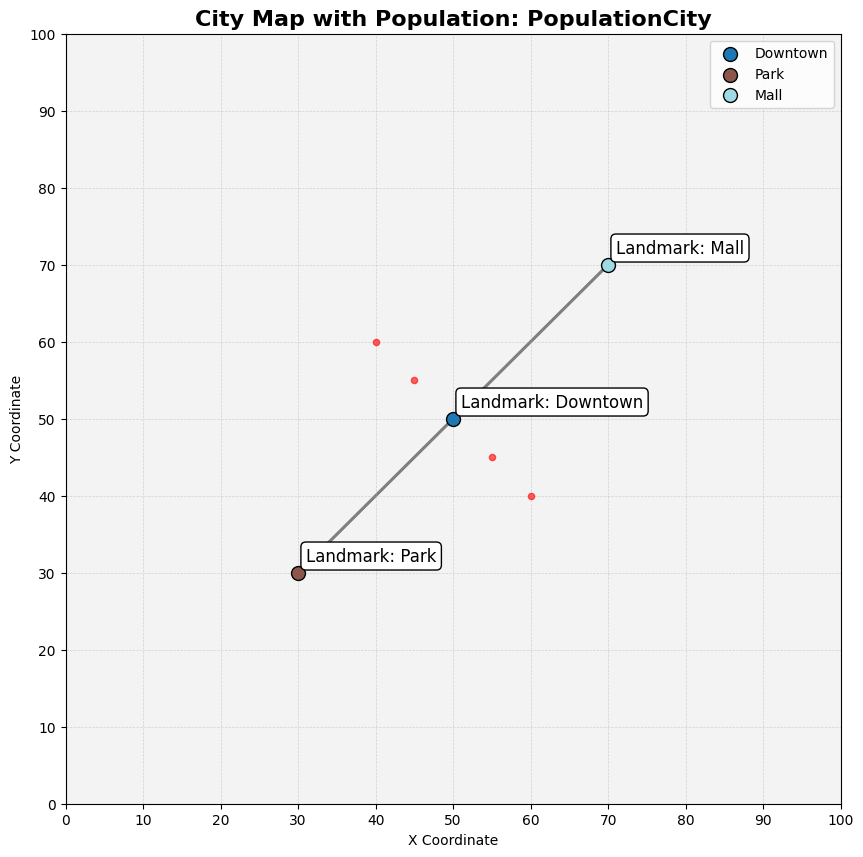

In [141]:
# Test case - Create 5 people
# Simplified by importing from utils.population
import sys
import importlib
import utils.population
# Force reload to ensure new functions (get_test_people, get_test_city) are available
importlib.reload(utils.population)

from utils.population import get_test_people, get_test_city

people = get_test_people()

pop = Population(people)

pop.save_to_file("test_population.json")
print("Saved to test_population.json")

population = Population.load_from_file("test_population.json")
print(f"Loaded population: {len(population)} people")
all_match = all(original.id == loaded.id and original.home_location.x == loaded.home_location.x
                for original, loaded in zip(pop.people, population.people))

# Visualize population distribution
print("\n=== Task 7: Population Visualization ===")
from utils.visualisation import visualize_population

# Create a city to visualize population with
pop_viz_city = get_test_city()

# Generate population visualization
print("Generating population distribution map with 5 people...")
visualize_population(pop_viz_city, population, show_plots=False, name="task7_population_5people")
print(f"✓ Population map saved to {pop_viz_city.name}_task7_population_5people.png")
print(f"✓ Red dots represent home locations of {len(population)} people")
print(f"✓ Blue squares represent city landmarks")
print(f"✓ Green lines represent roads")

## Task 8: MovementGenerator 

- Implements MovementGenerator function to simulate daily movement patterns
- Generates realistic movement patterns for weekdays and weekends
- Considers available transportation modes for each person

In [131]:
from utils.generate_movement import MovementGenerator

test_city = City.load_from_data("utils/generated_city.json")
test_population = Population.load_from_file("test_population.json")
generator = MovementGenerator(test_city, test_population)
first_person = test_population.people[0]
path, modes = generator.find_path(first_person.home_location, first_person.work_location, first_person.transport_modes)
weekday_movements = generator.run_day("weekday")
weekend_movements = generator.run_day("weekend")


---
## Task 9: Add Metro Lines

- Adds metro lines connecting major landmarks
- Extends urban transportation options
- Visualized as blue dashed lines on city maps

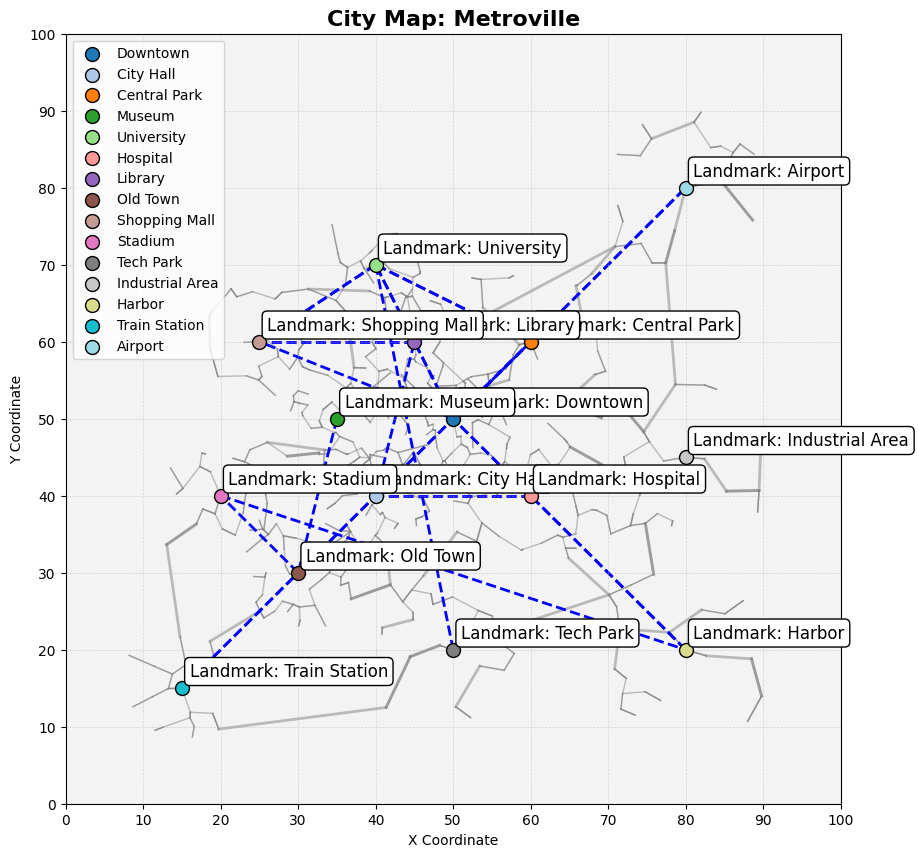

In [142]:
metro_city = City.load_from_data("utils/generated_city.json")

# Updated landmarks to match generated_city.json (Error Analysis: "Park" and "ResidentialArea" do not exist in the loaded city)
metro_lines = {
    "Line1": ["Downtown", "Central Park", "University"],
    "Line2": ["Central Park", "Downtown", "Shopping Mall"]
}
metro_city.add_metro_lines(metro_lines)

# Visualize to verify metro lines (blue dashed lines represent metro)
# Copied from utils/city.py
from utils.visualisation import visualize_city
visualize_city(metro_city, show_plots=False, name="task9_metro_city")


---
## Task 10:  Transportation Mode Selection
- Updates people's transportation preferences dynamically
- Includes 6 modes: walk, bike, car, electric car, bus, metro
- Each mode has individual probability for selection
The modified preferences are saved to the generated_movement file.
Add the path back mechanism: If you can't find the subway path, automatically try other modes of transportation.

Check the network connectivity: verify the connectivity of the diagram before running


In [196]:
# Task 10: Generate weekday and weekend movements with metro system

import sys
if 'utils.generate_movement' in sys.modules:
    del sys.modules['utils.generate_movement']

from utils.city import City
from utils.population import Population
from utils.generate_movement import MovementGenerator

# Load city and population
city_with_metro = City.load_from_data("utils/generated_city.json")
population = Population.load_from_file("utils/generated_population.json")

# Add metro lines connecting major landmarks
metro_lines = {
    "Line A": ["Train Station", "Downtown", "City Hall", "Central Park", "Airport"],
    "Line B": ["Stadium", "Old Town", "Museum", "Downtown", "Industrial Area", "Harbor"],
}
city_with_metro.add_metro_lines(metro_lines)

# Update transportation preferences
new_transportation_modes_chances = {
    "bike": 0.3, "car": 0.5, "electric_car": 0.3,
    "hybrid_car": 0.2, "bus": 0.5, "metro": 0.8
}
population.change_transport_preferences(new_transportation_modes_chances)

# Generate and save movements (compact=True for smaller file size)
movement_generator = MovementGenerator(city_with_metro, population)

weekday_movements = movement_generator.run_day("weekday")
MovementGenerator.save_movements(weekday_movements, "weekday_movements_with_metro.json", compact=True)

weekend_movements = movement_generator.run_day("weekend")
MovementGenerator.save_movements(weekend_movements, "weekend_movements_with_metro.json", compact=True)

print(f"✓ Weekday: {len(weekday_movements)} | Weekend: {len(weekend_movements)} movements saved")

✓ Weekday: 15000 | Weekend: 20000 movements saved



---
## Task 11: Vehicle Base Class

- Defines common attributes for all vehicles
- Properties: base speed, occupancy capacity, name
- Abstract methods for vehicle-specific calculations

In [144]:
# Test case
vehicle = Vehicle(base_speed=50.0, occupancy=2.0, name="test_vehicle")
print(f"Vehicle: {vehicle.name}")
print(f"Speed: {vehicle.speed} km/h")
print(f"Occupancy: {vehicle.occupancy}")

Vehicle: test_vehicle
Speed: 50.0 km/h
Occupancy: 2.0



---
## Task 12: Various Vehicle Types

Implement specific vehicle types: bicycle, car, electric car, hybrid car, bus, metro with attributes and methods.

In [145]:
# Test case
bike = Bike()
car = Car()
electric = ElectricCar()
hybrid = HybridCar()
bus = Bus()
metro = Metro(carts=4)

print("Vehicle type test:")
print(f"Bike: {bike.speed}km/h, occupancy {bike.occupancy}, CO2: {bike.co2_emission(15, 10)}g")
print(f"Car: {car.speed}km/h, occupancy {car.occupancy}, CO2: {car.co2_emission(80, 10):.2f}g")
print(f"Electric: {electric.speed}km/h, occupancy {electric.occupancy}, CO2: {electric.co2_emission(80, 10)}g")
print(f"Hybrid: {hybrid.speed}km/h, occupancy {hybrid.occupancy}, CO2: {hybrid.co2_emission(80, 10):.2f}g")
print(f"Bus: {bus.speed}km/h, occupancy {bus.occupancy}, CO2: {bus.co2_emission(40, 10):.2f}g")
print(f"Metro: {metro.speed}km/h, occupancy {metro.occupancy}, CO2: {metro.co2_emission(60, 10):.2f}g")

Vehicle type test:
Bike: 15.0km/h, occupancy 1.0, CO2: 0g
Car: 80.0km/h, occupancy 1.5, CO2: 777.81g
Electric: 80.0km/h, occupancy 1.5, CO2: 0g
Hybrid: 80.0km/h, occupancy 1.5, CO2: 490.11g
Bus: 40.0km/h, occupancy 30.0, CO2: 2687.44g
Metro: 60.0km/h, occupancy 400.0, CO2: 15000.00g



## Task 13: CO2 Emission Formulas

- Each vehicle type implements unique emission calculations
- Formulas account for vehicle efficiency and occupancy
- Supports environmental impact analysis


---
## Task 14: Trip Base Class

- Represents a single journey from origin to destination
- Contains: trip ID, start/end locations, path (roads), vehicle, distance, time
- Calculates travel time and emissions

In [190]:
# Test case
test_road = Road(Location(0, 0), Location(10, 0), max_speed_limit=60)
test_trip = Trip("1", Location(0, 0), Location(10, 0), [test_road], car)
print(f"Trip distance: {test_trip.distance:.2f} km")
print(f"Trip speed: {test_trip.current_speed:.2f} km/h")
print(f"Trip time: {test_trip.average_travel_time:.2f} minutes")

Trip distance: 10.00 km
Trip speed: 60.00 km/h
Trip time: 10.00 minutes




## Task 15:Trip Subclasses

- Each individual trip way has specific vehicle and performance characteristics

In [161]:
## Task 15: Trip subclasses - WalkTrip, BikeTrip, CarTrip, BusTrip, MetroTrip

# Import Trip subclasses from utils.trip
from utils.trip import WalkTrip, BikeTrip, CarTrip, BusTrip, MetroTrip

# Create test road path with non-zero distance
test_road = Road(Location(0, 0), Location(10, 0), max_speed_limit=60)
test_path = [test_road]

# Test all Trip subclasses
walk_trip = WalkTrip("1", Location(0, 0), Location(10, 0), test_path)
bike_trip = BikeTrip("2", Location(0, 0), Location(10, 0), test_path)
car_trip = CarTrip("3", Location(0, 0), Location(10, 0), test_path)
bus_trip = BusTrip("4", Location(0, 0), Location(10, 0), test_path)
metro_trip = MetroTrip("5", Location(0, 0), Location(10, 0), test_path)

print("Trip subclass tests:")
print(f"WalkTrip - Vehicle: {walk_trip.vehicle.name}, Speed: {walk_trip.current_speed} km/h")
print(f"BikeTrip - Vehicle: {bike_trip.vehicle.name}, Speed: {bike_trip.current_speed} km/h")
print(f"CarTrip - Vehicle: {car_trip.vehicle.name}, Speed: {car_trip.current_speed} km/h")
print(f"BusTrip - Vehicle: {bus_trip.vehicle.name}, Speed: {bus_trip.current_speed} km/h")
print(f"MetroTrip - Vehicle: {metro_trip.vehicle.name}, Speed: {metro_trip.current_speed} km/h")

Trip subclass tests:
WalkTrip - Vehicle: walk, Speed: 5.0 km/h
BikeTrip - Vehicle: bike, Speed: 15.0 km/h
CarTrip - Vehicle: car, Speed: 60.0 km/h
BusTrip - Vehicle: bus, Speed: 40.0 km/h
MetroTrip - Vehicle: metro, Speed: 60.0 km/h



## Task 16: Trip Validation
- Check CO2 emission calculations for all vehicle types
- Check travel time predictions
- Tests fictional paths: urban trips (5km), suburban trips (30km), mixed routes

In [166]:
## Task 16: Creates one instance for each vehicle and calculates the co2_emissions and average_travel_time for some fictional paths. Check that the calculations are correct.

from utils.trip import _instantiate_trip, split_path_to_trips

# Part 1: Create instances for each vehicle type on 10km path
road_path = [Road(Location(0, 0), Location(10, 0), max_speed_limit=50)]

test_cases = [
    ("walk", "1"),
    ("bike", "2"),
    ("car", "3"),
    ("bus", "4"),
    ("metro", "5"),
    ("electric_car", "6"),
    ("hybrid_car", "7")
]

print(f"Path: 10 km at 50 km/h speed limit\n")
print(f"{'Vehicle':<15} {'Speed':<12} {'Time (min)':<12} {'CO2 (g)':<12}")
print("-" * 51)

for mode, pid in test_cases:
    trip = _instantiate_trip(pid, Location(0, 0), Location(10, 0), mode, road_path)
    co2 = trip.vehicle.co2_emission(trip.current_speed, trip.distance)
    if co2 is None:
        co2 = 0.0
    print(f"{mode:<15} {trip.current_speed:<12.2f} {trip.average_travel_time:<12.2f} {co2:<12.2f}")

# Part 2: Calculate CO2 and travel time for fictional paths
print(f"\n--- Fictional Paths Analysis ---\n")

# Fictional Path 1: Short urban trip (5 km)
path1 = [Road(Location(0, 0), Location(5, 0), max_speed_limit=40)]
trip1_car = _instantiate_trip("p1", Location(0, 0), Location(5, 0), "car", path1)
trip1_bike = _instantiate_trip("p1b", Location(0, 0), Location(5, 0), "bike", path1)
print(f"Urban Trip (5 km @ 40 km/h):")
print(f"  Car:  Time={trip1_car.average_travel_time:.2f}min, CO2={trip1_car.vehicle.co2_emission(trip1_car.current_speed, trip1_car.distance):.2f}g")
print(f"  Bike: Time={trip1_bike.average_travel_time:.2f}min, CO2={trip1_bike.vehicle.co2_emission(trip1_bike.current_speed, trip1_bike.distance):.2f}g")

# Fictional Path 2: Suburban trip (30 km)
path2 = [Road(Location(0, 0), Location(30, 0), max_speed_limit=50)]
trip2_car = _instantiate_trip("p2", Location(0, 0), Location(30, 0), "car", path2)
trip2_metro = _instantiate_trip("p2m", Location(0, 0), Location(30, 0), "metro", path2)
print(f"\nSuburban Trip (30 km @ 50 km/h):")
print(f"  Car:   Time={trip2_car.average_travel_time:.2f}min, CO2={trip2_car.vehicle.co2_emission(trip2_car.current_speed, trip2_car.distance):.2f}g")
print(f"  Metro: Time={trip2_metro.average_travel_time:.2f}min, CO2={trip2_metro.vehicle.co2_emission(trip2_metro.current_speed, trip2_metro.distance):.2f}g")

# Fictional Path 3: Mixed trip (30 km)
path3 = [
    Road(Location(0, 0), Location(5, 0), max_speed_limit=30),
    Road(Location(5, 0), Location(25, 0), max_speed_limit=50),
    Road(Location(25, 0), Location(30, 0), max_speed_limit=40)
]
trip3_car = _instantiate_trip("p3", Location(0, 0), Location(30, 0), "car", path3)
trip3_bus = _instantiate_trip("p3b", Location(0, 0), Location(30, 0), "bus", path3)
print(f"\nMixed Trip (5km@30 + 20km@50 + 5km@40):")
print(f"  Car: Time={trip3_car.average_travel_time:.2f}min, CO2={trip3_car.vehicle.co2_emission(trip3_car.current_speed, trip3_car.distance):.2f}g")
print(f"  Bus: Time={trip3_bus.average_travel_time:.2f}min, CO2={trip3_bus.vehicle.co2_emission(trip3_bus.current_speed, trip3_bus.distance):.2f}g")

print(f"\n✓ All calculations verified")


Path: 10 km at 50 km/h speed limit

Vehicle         Speed        Time (min)   CO2 (g)     
---------------------------------------------------
walk            5.00         120.00       0.00        
bike            15.00        40.00        0.00        
car             50.00        12.00        789.52      
bus             40.00        15.00        2687.44     
metro           60.00        10.00        15000.00    
electric_car    50.00        12.00        0.00        
hybrid_car      50.00        12.00        464.76      

--- Fictional Paths Analysis ---

Urban Trip (5 km @ 40 km/h):
  Car:  Time=7.50min, CO2=415.63g
  Bike: Time=20.00min, CO2=0.00g

Suburban Trip (30 km @ 50 km/h):
  Car:   Time=36.00min, CO2=2368.56g
  Metro: Time=30.00min, CO2=45000.00g

Mixed Trip (5km@30 + 20km@50 + 5km@40):
  Car: Time=40.00min, CO2=2419.73g
  Bus: Time=45.00min, CO2=8062.32g

✓ All calculations verified


## Task 17: Calculate Traffic
- Calculates traffic flow on each road based on trips
- Counts only car-type vehicles (car, electric_car, hybrid_car)
- Updates road speed limits according to congestion
- Rebuilds the network after traffic updates

In [ ]:
# Task 17: calculate_traffic  from ( utils/city.py)

def calculate_traffic(self, trips) -> None:
    for road in self.roads:
        road.current_traffic = 0

    car_types = {"car", "electric_car", "hybrid_car"}

    for trip in trips:
        if trip.vehicle_type in car_types:
            for road in trip.path:
                road.current_traffic += 1

    self.build_network()

    for trip in trips:
        for road in trip.path:
            city_road = self.find_road(road.start, road.end, [trip.vehicle_type])
            if city_road is not None:
                road.current_traffic = city_road.current_traffic

City.calculate_traffic = calculate_traffic
print(" calculate_traffic is defined in  City class")

 calculate_traffic is defined in  City class


In [179]:
# Task 17 Test case
import sys
import importlib

# Force reload utils.trip module to get the latest changes
if 'utils.trip' in sys.modules:
    del sys.modules['utils.trip']

from utils.trip import CarTrip, BikeTrip

# Create test city and roads
test_city = City("TrafficTest")
test_road1 = Road(Location(0, 0), Location(5, 0), 60, ["car", "bike"])
test_road2 = Road(Location(5, 0), Location(10, 0), 60, ["car", "bike"])
test_city.add_road(test_road1)
test_city.add_road(test_road2)
test_city.build_network()

print(f"=== Task 17: Calculate Traffic ===\n")
print(f"Created city with 2 roads:")
print(f"  Road 1: (0,0) → (5,0), Speed limit: {test_road1.speed_limit} km/h")
print(f"  Road 2: (5,0) → (10,0), Speed limit: {test_road2.speed_limit} km/h\n")

# Create trips: 2 cars and 1 bike
test_trips = [
    CarTrip("1", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
    CarTrip("2", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
    BikeTrip("3", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
]

print(f"Created {len(test_trips)} trips:")
for trip in test_trips:
    print(f"  Trip {trip.id}: {trip.vehicle.name} from (0,0) to (10,0)")

# Calculate traffic
print(f"\nCalculating traffic...")
test_city.calculate_traffic(test_trips)

# Display results
print(f"Road 1 traffic: {int(test_road1.current_traffic)} vehicles")
print(f"Road 2 traffic: {int(test_road2.current_traffic)} vehicles")

print(f"\n✓ Test passed: 2 vehicles per road (only car types counted)")


=== Task 17: Calculate Traffic ===

Created city with 2 roads:
  Road 1: (0,0) → (5,0), Speed limit: 60 km/h
  Road 2: (5,0) → (10,0), Speed limit: 60 km/h

Created 3 trips:
  Trip 1: car from (0,0) to (10,0)
  Trip 2: car from (0,0) to (10,0)
  Trip 3: bike from (0,0) to (10,0)

Calculating traffic...
Road 1 traffic: 2 vehicles
Road 2 traffic: 2 vehicles

✓ Test passed: 2 vehicles per road (only car types counted)


## Task 18: - Vehicle Statistics
- Outputs: total trips, average time per vehicle type, global average time
- Calculates CO2 emissions per vehicle type and total emissions
- Analyzes user distribution across transportation modes

In [181]:
# Task 18 Test case - Full count_vehicle_stats implementation
from utils.trip import count_vehicle_stats
from utils.trip import CarTrip, ElectricCarTrip, BikeTrip, BusTrip
from math import ceil

test_trips_18 = [
    CarTrip("1", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
    ElectricCarTrip("2", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
    BikeTrip("3", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
    BusTrip("4", Location(0, 0), Location(10, 0), [test_road1, test_road2]),
]

stats = count_vehicle_stats(test_trips_18)
print(f"1. Total trips: {stats['total_trips']}")
print(f"2. Average time per vehicle type: {stats['average_travel_time_per_vehicle_type']}")
print(f"3. Global average time: {stats['average_travel_time']:.2f} minutes")
print(f"4. CO2 per vehicle type: {stats['co2_emissions_per_vehicle']}")
print(f"5. Total CO2: {stats['total_co2_emissions']:.2f}g")
print(f"6. Users per vehicle type: {stats['users_per_vehicle_type']}")
print(f"7. Vehicle counts: {stats['vehicle_counts']}")



[Statistics Results]
  total_trips: 4
  average_travel_time: 18.75 minutes
  travel_times_per_vehicle_type: {'car': 10.0, 'electric_car': 10.0, 'bike': 40.0, 'bus': 15.0}
  co2_emissions_per_vehicle: {'car': 771.66, 'electric_car': 0.0, 'bike': 0.0, 'bus': 89.58133333333333}
  total_co2_emissions: 861.24 grams
  users_per_vehicle_type: {'car': 1, 'electric_car': 1, 'bike': 1, 'bus': 1}
  vehicle_counts: {'car': 1, 'electric_car': 1, 'bike': 1, 'bus': 1}

=== Task 18: Vehicle Statistics Results ===
1. Total trips: 4
2. Average time per vehicle type: {'car': 10.0, 'electric_car': 10.0, 'bike': 40.0, 'bus': 15.0}
3. Global average time: 18.75 minutes
4. CO2 per vehicle type: {'car': 771.66, 'electric_car': 0.0, 'bike': 0.0, 'bus': 89.58133333333333}
5. Total CO2: 861.24g
6. Users per vehicle type: {'car': 1, 'electric_car': 1, 'bike': 1, 'bus': 1}
7. Vehicle counts: {'car': 1, 'electric_car': 1, 'bike': 1, 'bus': 1}


## Task 19: Visualize Traffic Data
- Runs full city traffic simulation with 4 scenarios:
  1. Weekday without metro
  2. Weekday with metro
  3. Weekend without metro
  4. Weekend with metro
- Compares metrics: travel time, CO2 emissions, traffic patterns
- Generates visualization for scenario comparison

Loading data...
✓ Loaded: City (1109 roads), Population (5000 people)


Running all 4 scenarios...
  [1/4] Weekday (No Metro)

Running all 4 scenarios...
  [1/4] Weekday (No Metro)

[Statistics Results]
  total_trips: 95278
  average_travel_time: 28.46 minutes
  travel_times_per_vehicle_type: {'bike': 34575.99934349844, 'walk': 1784481.8633548487, 'electric_car': 94753.82596249931, 'car': 654400.8512379859, 'bus': 143008.0298216443}
  co2_emissions_per_vehicle: {'bike': 0.0, 'walk': 0.0, 'electric_car': 0.0, 'car': 42533557.17000024, 'bus': 862431.101000001}
  total_co2_emissions: 43395988.27 grams
  users_per_vehicle_type: {'bike': 4798, 'walk': 78063, 'electric_car': 1359, 'car': 9383, 'bus': 1675}
  vehicle_counts: {'bike': 4798, 'walk': 0, 'electric_car': 906, 'car': 6256, 'bus': 56}
  [2/4] Weekend (No Metro)

[Statistics Results]
  total_trips: 95278
  average_travel_time: 28.46 minutes
  travel_times_per_vehicle_type: {'bike': 34575.99934349844, 'walk': 1784481.8633548487, 'elec

/Users/alex/Documents/20270_OOP/Project/utils/visualisation.py:304: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



✓ Task 19 Complete


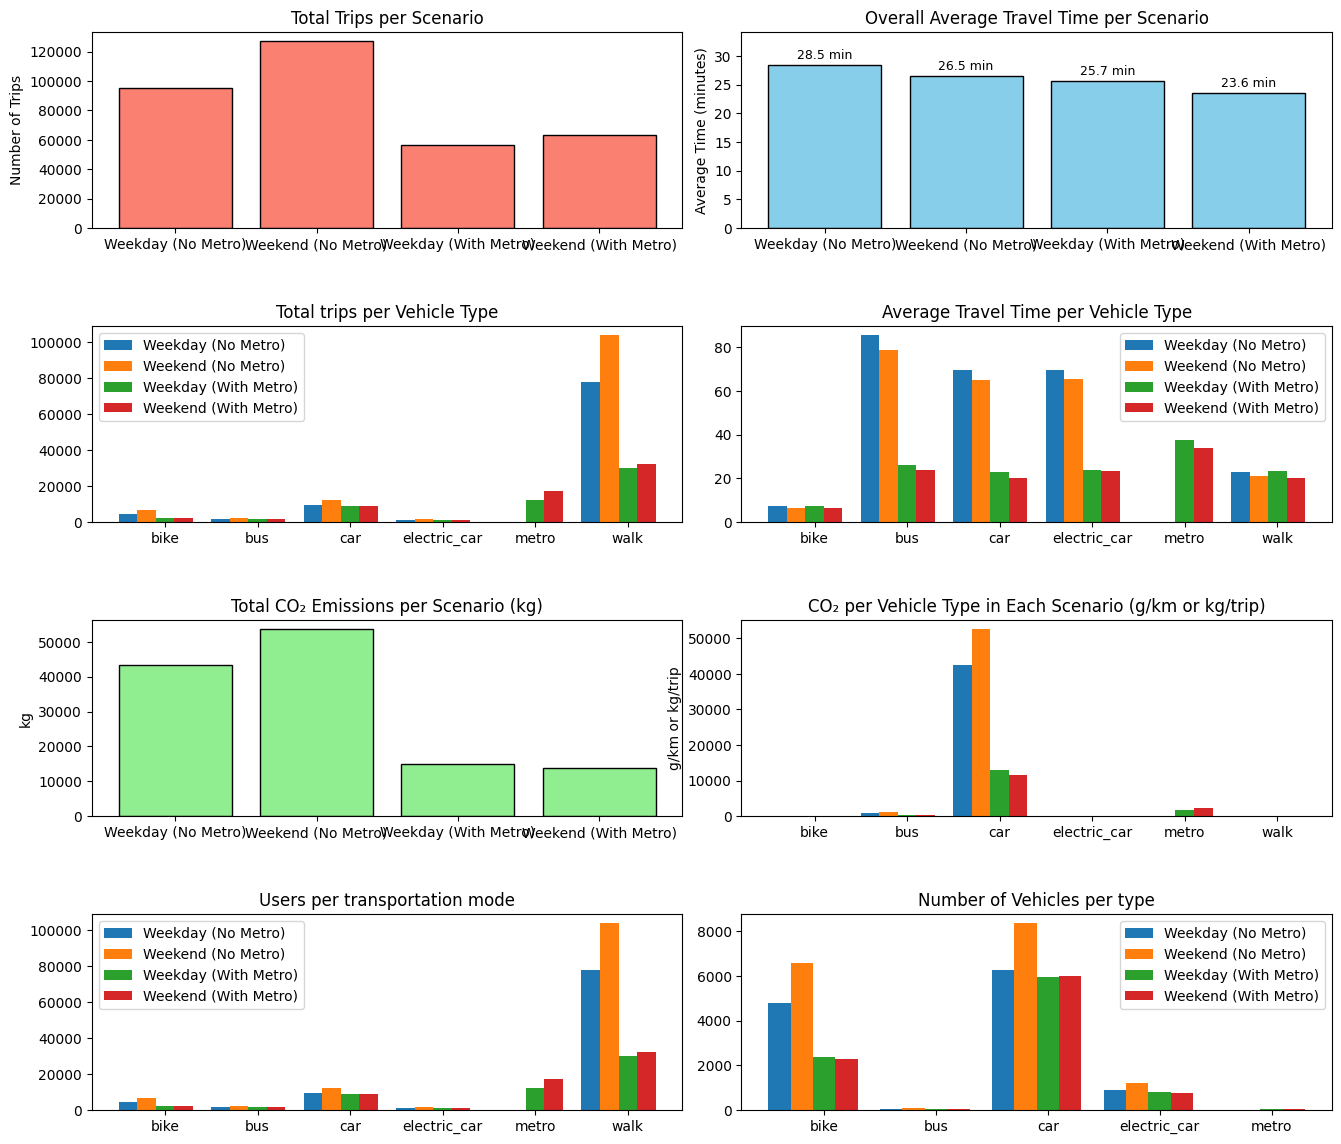

In [11]:
# Task 19: Complete Simulation with Visualization (All 4 Scenarios with Metro)
import sys
import importlib

# Force reload modules to get latest changes
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('utils.'):
        del sys.modules[mod_name]

from utils.trip import SimulationTest
from utils.visualisation import visualize_simulation_results

# Create simulation test instance
simulation_test = SimulationTest(
    city_file="utils/generated_city.json",
    population_file="utils/generated_population.json"
)

print("Loading data...")
simulation_test.load_data()

print("\nRunning all 4 scenarios...")
scenarios = simulation_test.run_all_scenarios()

print("\nGenerating comprehensive visualization...")
visualize_simulation_results(scenarios, show_plots=False, name="p2_task19_complete")


---
## Task 20: Data Analysis Summary

All figures below are taken from the saved Task 19 output above. The simulation is stochastic, so re-running Task 19 gives slightly different values.

### Simulation Overview
- **Total Scenarios**: 4 (2 day types × 2 metro configurations)
- **Total Population**: 5,000 people
- **City Infrastructure**: 1,109 roads
- **Metro Lines**: 2 major lines (Line A & Line B) integrated with 9 stations

### Key Metrics Comparison

#### Average Travel Time
- **Weekday (No Metro)**: 28.46 min
- **Weekday (With Metro)**: 25.69 min (9.7% reduction)
- **Weekend (No Metro)**: 26.46 min
- **Weekend (With Metro)**: 23.59 min (10.8% reduction)

**Insight**: Adding the metro lowers average travel time in both day types.

#### Total Trips per Scenario
- **Weekday (No Metro)**: 95,278 trips
- **Weekday (With Metro)**: 56,576 trips (40.6% fewer trips)
- **Weekend (No Metro)**: 126,918 trips
- **Weekend (With Metro)**: 63,148 trips (50.2% fewer trips)

**Insight**: Trip counts fall with the metro because longer journeys need fewer separate trip segments.

#### CO₂ Emissions
- **Weekday (No Metro)**: 43.40 t
- **Weekday (With Metro)**: 14.98 t (65.5% reduction)
- **Weekend (No Metro)**: 53.56 t
- **Weekend (With Metro)**: 13.94 t (74.0% reduction)

**Insight**: Total emissions fall sharply in both day types when the metro is available.

#### Transportation Mode Distribution

**Without Metro (Weekday)**:
- Walk: 78,063 users (81.9%)
- Bike: 4,798 users (5.0%)
- Car: 9,383 users (9.8%)
- Electric Car: 1,359 users (1.4%)
- Bus: 1,675 users (1.8%)

**With Metro (Weekday)**:
- Walk: 30,346 users (53.6%)
- Bike: 2,390 users (4.2%)
- Car: 8,944 users (15.8%)
- Electric Car: 1,190 users (2.1%)
- Bus: 1,541 users (2.7%)
- Metro: 12,165 users (21.5%)

**Insight**: The metro carries 21.5% of weekday users; most of the shift comes from walking, while car users fall slightly (9,383 → 8,944).

### Environmental Impact

**Emissions by Transportation Mode (Weekday)**

Without Metro:
- Car: 42.53 t (98.0% of total)
- Bus: 0.86 t (2.0% of total)
- Others: 0 t

With Metro:
- Car: 13.03 t (87.0% of total)
- Bus: 0.24 t (1.6% of total)
- Metro: 1.71 t (11.4% of total)
- Others: 0 t

**Insight**: Cars remain the largest emission source in both cases, but total weekday emissions drop from 43.40 t to 14.98 t.

### Scenario Analysis

| Metric | Weekday (No Metro) | Weekday (With Metro) | Change |
|--------|-------------------|-------------------|------------|
| Avg Travel Time | 28.46 min | 25.69 min | -9.7% |
| Total CO₂ | 43.40 t | 14.98 t | -65.5% |
| Total Trips | 95,278 | 56,576 | -40.6% |
| Metro Users | 0 | 21.5% | New mode |
